In [1]:
from PIL import Image
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import random
from tqdm import tqdm

random.seed(42)

'''
    0: background
    1: neutrophil
    2: epithelial
    3: lymphocyte
    4: plasma
    5: eosinophil
    6: connective
'''


'\n    0: background\n    1: neutrophil\n    2: epithelial\n    3: lymphocyte\n    4: plasma\n    5: eosinophil\n    6: connective\n'

In [2]:
filenames = pd.read_csv('patch_info.csv')
filenames = filenames['patch_info'].to_list()
len(filenames)

4981

In [3]:
images, labels = np.load('./images.npy'), np.load('./labels.npy')[..., -1]

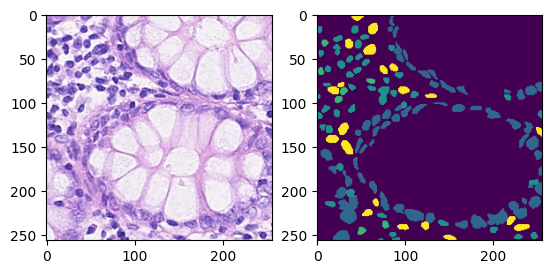

In [4]:
fig, axes = plt.subplots(1, 2)
axes[0].imshow(images[10])
axes[1].imshow(labels[10])
plt.show()




In [5]:
save_dir = 'data'
image_root = os.path.join(save_dir, 'images')
label_root = os.path.join(save_dir, 'annotations')
os.makedirs(image_root, exist_ok=True)
os.makedirs(label_root, exist_ok=True)

palette = [
    0, 0, 0,
    255, 0, 0,
    0, 255, 0,
    0, 0, 255,
    255, 255, 0,
    255, 0, 255,
    0, 255, 255,
] + [0, 0, 0] * (256 - 7)

for i in range(len(filenames)):
    image_path = os.path.join(image_root, filenames[i]+'.png')
    label_path = os.path.join(label_root, filenames[i]+'.png')
    image = Image.fromarray(images[i].astype(np.uint8))
    label = Image.fromarray(labels[i].astype(np.uint8))
    label.putpalette(palette)
    image.save(image_path)
    label.save(label_path)

In [6]:
import shutil
import random
from sklearn.model_selection import train_test_split
from tqdm import tqdm
def split_filenames(filenames, train_ratio=0.8, val_ratio=0.1, test_ratio=0.1, random_seed=42):
    random.seed(random_seed)
    np.random.seed(random_seed)
    
    assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6

    train_val_files, test_files = train_test_split(
        filenames, 
        test_size=test_ratio, 
        random_state=random_seed
    )

    val_size = val_ratio / (train_ratio + val_ratio) 
    train_files, val_files = train_test_split(
        train_val_files,
        test_size=val_size,
        random_state=random_seed
    )
    
    print(f"total_samples: {len(filenames)}")
    print(f"train_samples: {len(train_files)} ({len(train_files)/len(filenames)*100:.1f}%)")
    print(f"val_samples: {len(val_files)} ({len(val_files)/len(filenames)*100:.1f}%)")
    print(f"test_samples: {len(test_files)} ({len(test_files)/len(filenames)*100:.1f}%)")
    
    return train_files, val_files, test_files

train_files, validation_files, test_files = split_filenames(filenames)

output_dir = './data_split'
splits = ['train', 'validation', 'test']
for split in splits:
    os.makedirs(os.path.join(output_dir, 'images', split), exist_ok=True)
    os.makedirs(os.path.join(output_dir, 'annotations', split), exist_ok=True)

def move_files(file_list, split_name, source_dir, target_dir):
    print(f"\n{split_name}...")
    for filename in tqdm(file_list, desc=f"moving {split_name} set"):
        src_img = os.path.join(source_dir, 'images', f"{filename}.png")
        dst_img = os.path.join(target_dir, 'images', split_name, f"{filename}.png")
        if os.path.exists(src_img):
            shutil.copy(src_img, dst_img)
        src_ann = os.path.join(source_dir, 'annotations', f"{filename}.png")
        dst_ann = os.path.join(target_dir, 'annotations', split_name, f"{filename}.png")
        if os.path.exists(src_ann):
            shutil.copy(src_ann, dst_ann)

source_data_dir = './data'
move_files(train_files, 'train', source_data_dir, output_dir)
move_files(validation_files, 'validation', source_data_dir, output_dir)
move_files(test_files, 'test', source_data_dir, output_dir)









total_samples: 4981
train_samples: 3983 (80.0%)
val_samples: 499 (10.0%)
test_samples: 499 (10.0%)

train...


moving train set: 100%|██████████| 3983/3983 [00:00<00:00, 4413.16it/s]



validation...


moving validation set: 100%|██████████| 499/499 [00:00<00:00, 5791.71it/s]



test...


moving test set: 100%|██████████| 499/499 [00:00<00:00, 6622.84it/s]
